# Queue Cartography — training & evaluating the clinic wait-time network

**Question:** how do staffing and queue size affect clinic wait times?
A small neural network learns to predict a visitor's wait (in minutes) from four things a clinic manager can see:
the **hour**, the **weekday**, the **staff on shift**, and the **patients already in the queue**.
The trained network is exported to ONNX and runs in the browser exhibit, where visitors move sliders and the
model predicts the wait live.

**Data:** `clinic-wait-times.csv` from the course site
(<https://snsie.github.io/neural-networks/data/clinic-wait-times.csv>) — **2,000 simulated (synthetic) visits**.
The data is made up; nothing here describes a real clinic or real patients.

**Plan of this notebook**

| § | Step | Assignment requirement |
|---|------|------|
| 1 | Data audit | — |
| 2 | Problem definition: inputs, output, metrics | define inputs/outputs |
| 3 | Train / validation / test split — test set sealed | keep a separate test set |
| 4 | Exploration (training split only) | — |
| 5 | Baselines | compare with a simple baseline |
| 6 | Neural network: model, training, small sweep on validation | train a small NN |
| 7 | **One-time test-set evaluation** | compare on the test set |
| 8 | The biggest mistake | explain one mistake |
| 9 | What the network learned | the exhibit's discovery |
| 10 | Export to ONNX + parity check, write web artifacts | runs in the browser |

## 0 · Setup

In [1]:
import json
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime
import pandas as pd
import sklearn
import torch
from sklearn.linear_model import LinearRegression
from IPython.display import display

import wait_model as wm

wm.set_determinism(wm.SEED)
FIG = wm.ROOT / "training" / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
STAFF_COLORS = {s: matplotlib.colormaps["viridis"](0.1 + 0.2 * (s - 1)) for s in wm.STAFF}

versions = {
    "python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__,
    "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "onnx": onnx.__version__,
    "onnxruntime": onnxruntime.__version__,
}
print(versions)
print("seed:", wm.SEED, "| device: CPU | deterministic algorithms:", torch.are_deterministic_algorithms_enabled())

{'python': '3.14.8', 'torch': '2.15.0', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'onnx': '1.23.2', 'onnxruntime': '1.32.0'}
seed: 42 | device: CPU | deterministic algorithms: True


## 1 · Data audit

In [2]:
df = wm.load_data()
sha = wm.file_sha256()
print(f"rows: {len(df):,}  | columns: {list(df.columns[:5])}")
print("sha256:", sha)
print("missing values:", int(df.isna().sum().sum()))
display(df.head())
display(df.describe().round(2))

rows: 2,000  | columns: ['hour', 'day_of_week', 'staff_on_shift', 'patients_in_queue', 'wait_minutes']
sha256: 75c2875ad4395fed204495d5fe17b373d8ddfb7ab82775ab1be9478fb1f40ce0
missing values: 0


,hour,day_of_week,staff_on_shift,patients_in_queue,wait_minutes,day_idx
0,8,Mon,1,13,196.8,0
1,14,Thu,1,20,305.8,3
2,15,Tue,3,17,103.9,1
3,11,Tue,4,17,64.7,1
4,16,Tue,2,14,119.2,1


,hour,staff_on_shift,patients_in_queue,wait_minutes,day_idx
count,2000.00,2000.00,2000.00,2000.00,2000.00
mean,12.50,2.97,10.10,78.06,2.02
std,2.93,1.39,6.19,66.70,1.41
min,8.00,1.00,0.00,0.00,0.00
25%,10.00,2.00,5.00,32.90,1.00
50%,13.00,3.00,10.00,58.55,2.00
75%,15.00,4.00,15.00,97.80,3.00
max,17.00,5.00,20.00,324.00,4.00


In [3]:
cells = df.groupby(["staff_on_shift", "patients_in_queue"]).size()
full = df.groupby(["hour", "day_of_week", "staff_on_shift", "patients_in_queue"]).size()
print(f"staff × queue cells covered: {len(cells)} / {5 * 21}")
print(f"full hour × day × staff × queue combinations covered: {len(full):,} / {10 * 5 * 5 * 21:,}")
print("visits per weekday:", df["day_of_week"].value_counts().reindex(wm.DAYS).to_dict())
zeros = df[df["wait_minutes"] == 0]
print(f"\nrows with a 0.0-minute wait: {len(zeros)}")
display(zeros)
q0 = df[df["patients_in_queue"] == 0]["wait_minutes"]
print(f"queue = 0 rows: n={len(q0)}, mean wait {q0.mean():.1f} min, max {q0.max():.1f} min")

staff × queue cells covered: 105 / 105
full hour × day × staff × queue combinations covered: 1,677 / 5,250
visits per weekday: {'Mon': 372, 'Tue': 429, 'Wed': 390, 'Thu': 401, 'Fri': 408}

rows with a 0.0-minute wait: 9


,hour,day_of_week,staff_on_shift,patients_in_queue,wait_minutes,day_idx
205,15,Fri,5,0,0.0,4
365,13,Mon,1,0,0.0,0
761,15,Wed,2,0,0.0,2
896,15,Thu,4,0,0.0,3
1037,15,Tue,1,0,0.0,1
1160,11,Tue,3,0,0.0,1
1312,13,Thu,4,0,0.0,3
1940,11,Thu,4,0,0.0,3
1959,14,Thu,5,2,0.0,3


queue = 0 rows: n=118, mean wait 9.6 min, max 25.8 min


The file is clean: no missing values, all four inputs are small integer ranges, and every staff × queue cell has
data. The few 0-minute waits are almost all visits with an empty queue, which is plausible.
Because the data is synthetic, there are no real-world quirks (no-shows, triage priority, closures) — a limitation
we state on the site.

## 2 · Problem definition

* **Inputs (4, raw):** `hour` (8–17), `day_of_week` (Mon–Fri), `staff_on_shift` (1–5), `patients_in_queue` (0–20).
  These are exactly the controls a visitor sets in the exhibit.
  We deliberately do **not** hand the network the `queue ÷ staff` ratio — we want to see whether it can discover
  that relationship from the raw inputs.
* **Encoding (inside the model):** hour → one-hot (10), weekday → one-hot (5), staff & queue → standardized with
  training-set mean/std. That is 17 numbers into the first layer. Hour is one-hot because its effect need not be a
  straight line (peaks can happen mid-morning and late afternoon).
* **Output:** predicted wait in minutes (regression).
* **Metrics:** MAE (mean absolute error, minutes) is the headline — it reads naturally ("off by X minutes on
  average"). We also report RMSE, R², and the share of visits predicted within ±10 minutes.

## 3 · Split: train 70% / validation 15% / test 15%

Stratified by `staff_on_shift` so each split sees every staffing level in the same proportions.
**The test set is sealed now and is not looked at again until §7** — all choices (model size, learning rate,
when to stop training) are made on the validation set.

In [4]:
train, val, test = wm.split_data(df)
assert set(train.index).isdisjoint(val.index) and set(train.index).isdisjoint(test.index) and set(val.index).isdisjoint(test.index)
assert len(train) + len(val) + len(test) == len(df)
print(f"train {len(train)} | validation {len(val)} | test {len(test)}  (seed {wm.SEED})")
display(pd.DataFrame({name: part["staff_on_shift"].value_counts(normalize=True).sort_index().round(3)
                      for name, part in [("train", train), ("val", val), ("test", test)]}))
scaling = wm.Scaling.from_train(train)
print("scaling (training split only):", scaling)

train 1400 | validation 300 | test 300  (seed 42)


,train,val,test
staff_on_shift,,,
1,0.195,0.193,0.197
2,0.216,0.217,0.213
3,0.200,0.200,0.200
4,0.204,0.203,0.203
5,0.186,0.187,0.187


scaling (training split only): Scaling(num_mean=[2.9692857142857143, 10.213571428571429], num_std=[1.3932693529235178, 6.135327569719085], y_mean=78.31242857142857, y_std=65.69420546170642)


## 4 · Exploration (training split only)

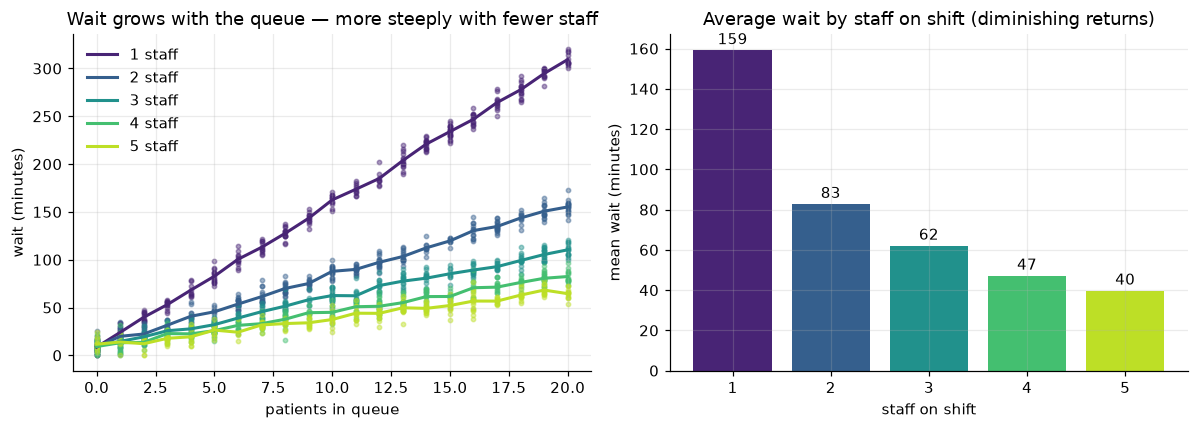

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for s in wm.STAFF:
    part = train[train["staff_on_shift"] == s]
    ax.scatter(part["patients_in_queue"], part["wait_minutes"], s=8, alpha=0.45, color=STAFF_COLORS[s])
    means = part.groupby("patients_in_queue")["wait_minutes"].mean()
    ax.plot(means.index, means.values, color=STAFF_COLORS[s], lw=2, label=f"{s} staff")
ax.set(title="Wait grows with the queue — more steeply with fewer staff",
       xlabel="patients in queue", ylabel="wait (minutes)")
ax.legend(frameon=False)

ax = axes[1]
by_staff = train.groupby("staff_on_shift")["wait_minutes"].mean()
ax.bar(by_staff.index, by_staff.values, color=[STAFF_COLORS[s] for s in by_staff.index])
for s, v in by_staff.items():
    ax.text(s, v + 3, f"{v:.0f}", ha="center")
ax.set(title="Average wait by staff on shift (diminishing returns)", xlabel="staff on shift",
       ylabel="mean wait (minutes)", xticks=wm.STAFF)
fig.tight_layout()
fig.savefig(FIG / "eda_queue_staff.png", bbox_inches="tight")
plt.show()

wait ≈ 14.97 × (queue ÷ staff) + 8.98   R² = 0.991


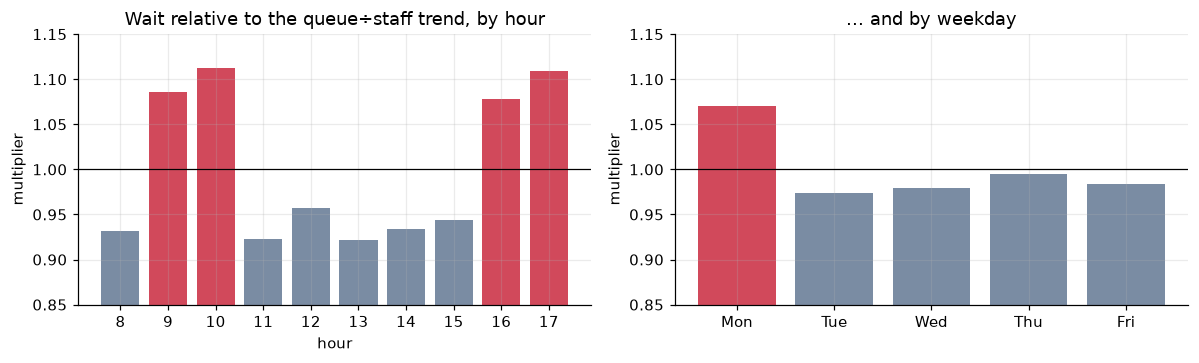

hour multipliers: {8: 0.932, 9: 1.086, 10: 1.113, 11: 0.923, 12: 0.957, 13: 0.921, 14: 0.934, 15: 0.944, 16: 1.078, 17: 1.109}
day multipliers: {'Mon': 1.07, 'Tue': 0.974, 'Wed': 0.979, 'Thu': 0.995, 'Fri': 0.984}


In [6]:
# How much of the pattern is "queue ÷ staff"? Fit wait ≈ a·(queue/staff) + b on training data,
# then look at what is left over by hour and weekday as a multiplier.
ratio_tr = (train["patients_in_queue"] / train["staff_on_shift"]).to_numpy()[:, None]
ratio_fit = LinearRegression().fit(ratio_tr, train["wait_minutes"])
print(f"wait ≈ {ratio_fit.coef_[0]:.2f} × (queue ÷ staff) + {ratio_fit.intercept_:.2f}   "
      f"R² = {ratio_fit.score(ratio_tr, train['wait_minutes']):.3f}")

busy = train[train["patients_in_queue"] > 0].copy()
busy["multiplier"] = busy["wait_minutes"] / ratio_fit.predict(
    (busy["patients_in_queue"] / busy["staff_on_shift"]).to_numpy()[:, None])
hour_mult = busy.groupby("hour")["multiplier"].mean()
day_mult = busy.groupby("day_of_week")["multiplier"].mean().reindex(wm.DAYS)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(hour_mult.index, hour_mult.values, color=["#d1495b" if v > 1.02 else "#7a8ca3" for v in hour_mult])
axes[0].axhline(1, color="k", lw=0.8)
axes[0].set(title="Wait relative to the queue÷staff trend, by hour", xlabel="hour", ylabel="multiplier",
            ylim=(0.85, 1.15), xticks=wm.HOURS)
axes[1].bar(day_mult.index, day_mult.values, color=["#d1495b" if v > 1.02 else "#7a8ca3" for v in day_mult])
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set(title="… and by weekday", ylabel="multiplier", ylim=(0.85, 1.15))
fig.tight_layout()
fig.savefig(FIG / "eda_hour_day.png", bbox_inches="tight")
plt.show()
print("hour multipliers:", hour_mult.round(3).to_dict())
print("day multipliers:", day_mult.round(3).to_dict())

Three patterns stand out in the training data:

1. **Queue ÷ staff explains almost everything.** Each patient ahead of you adds roughly a fixed number of minutes,
   divided across the staff on shift. That makes staffing a curve with **diminishing returns**: going from 1 to 2
   staff halves the wait; going from 4 to 5 trims only a little.
2. **Peak hours** (around 9–10 am and 4–5 pm) run several percent longer than the trend.
3. **Mondays** run a few percent longer than other weekdays.

A straight-line model in the raw inputs cannot represent "÷ staff", so it should struggle; a neural network can
bend to fit it.

## 5 · Baselines (fit on training data, compared on validation)

1. **Median baseline** — always predict the training median wait. This is the required simple baseline.
2. **Linear regression** on the same 17 encoded features the network sees.
3. **Queue ÷ staff formula** — `a·(queue/staff) + b`. Not a baseline a beginner would have, but a useful
   reference: it is close to how the data was generated, so it shows how much error is simply noise.

In [7]:
x_tr, y_tr = wm.inputs(train), wm.target(train)
x_va, y_va = wm.inputs(val), wm.target(val)
x_te, y_te = wm.inputs(test), wm.target(test)

median_wait = float(np.median(y_tr))
linear = LinearRegression().fit(wm.encode_numpy(x_tr, scaling), y_tr)

def ratio_feature(x):
    return (x[:, 3] / x[:, 2])[:, None]

ratio_model = LinearRegression().fit(ratio_feature(x_tr), y_tr)

baseline_predict = {
    "median_baseline": lambda x: np.full(len(x), median_wait),
    "linear": lambda x: linear.predict(wm.encode_numpy(x, scaling)),
    "ratio_formula": lambda x: ratio_model.predict(ratio_feature(x)),
}
print(f"training median wait = {median_wait:.1f} min")
val_table = pd.DataFrame({name: wm.regression_metrics(y_va, f(x_va)) for name, f in baseline_predict.items()}).T
display(val_table.round(3))

training median wait = 59.5 min


,mae,rmse,r2,within10
median_baseline,48.251,70.896,-0.067,0.170
linear,26.324,34.122,0.753,0.213
ratio_formula,5.639,7.143,0.989,0.837


## 6 · The neural network

`ExhibitModel` (in `wait_model.py`) is a small multilayer perceptron with the preprocessing built in, so the
exported ONNX file takes the **raw** four inputs:

```
raw (hour, day, staff, queue) ─► one-hot hour(10) + one-hot day(5) + standardized staff, queue (2)  = 17
                              ─► Linear 17→H1, ReLU ─► Linear H1→H2, ReLU ─► Linear H2→1 ─► minutes (≥ 0)
```

Training: Adam, mean-squared error on the standardized target, batch size 64, up to 3,000 epochs with
**early stopping on validation MAE** (patience 150 epochs; the best weights are restored).

Small hyper-parameter sweep — chosen **by validation MAE only**:
hidden sizes {(16, 8), (32, 16)} × learning rate {3e-3, 1e-3} × weight decay {0, 1e-4}.
If the smaller (16, 8) network is within 0.2 minutes of the best, we keep it: it is easier to show (and explain)
neuron-by-neuron in the exhibit's "network X-ray".

In [8]:
import itertools, time

sweep, results = [], {}
for hidden, lr, wd in itertools.product([(16, 8), (32, 16)], [3e-3, 1e-3], [0.0, 1e-4]):
    cfg = wm.TrainConfig(hidden=hidden, lr=lr, weight_decay=wd)
    t0 = time.time()
    res = wm.train_mlp(train, val, scaling, cfg)
    results[(hidden, lr, wd)] = res
    sweep.append({"hidden": list(hidden), "lr": lr, "weightDecay": wd, "valMae": res.best_val_mae,
                  "bestEpoch": res.best_epoch, "epochsRun": res.epochs_run, "seconds": round(time.time() - t0, 1)})
sweep_df = pd.DataFrame(sweep).sort_values("valMae")
display(sweep_df.style.format({"lr": "{:g}", "weightDecay": "{:g}", "valMae": "{:.3f}"}).hide(axis="index"))

hidden,lr,weightDecay,valMae,bestEpoch,epochsRun,seconds
"[16, 8]",0.001,0,4.600,497,647,1.900000
"[16, 8]",0.003,0.0001,4.677,119,269,0.800000
"[16, 8]",0.001,0.0001,4.679,333,483,1.400000
"[32, 16]",0.003,0.0001,4.690,44,194,0.600000
"[16, 8]",0.003,0,4.704,169,319,0.900000
"[32, 16]",0.001,0.0001,4.729,244,394,1.200000
"[32, 16]",0.003,0,4.857,44,194,0.600000
"[32, 16]",0.001,0,4.877,126,276,0.800000


best overall: hidden=(16, 8) val MAE 4.600
best (16, 8): lr=0.001 wd=0.0 val MAE 4.600
CHOSEN: hidden=(16, 8), lr=0.001, weight decay=0.0, best epoch 497 of 647, val MAE 4.600
trainable parameters: 433


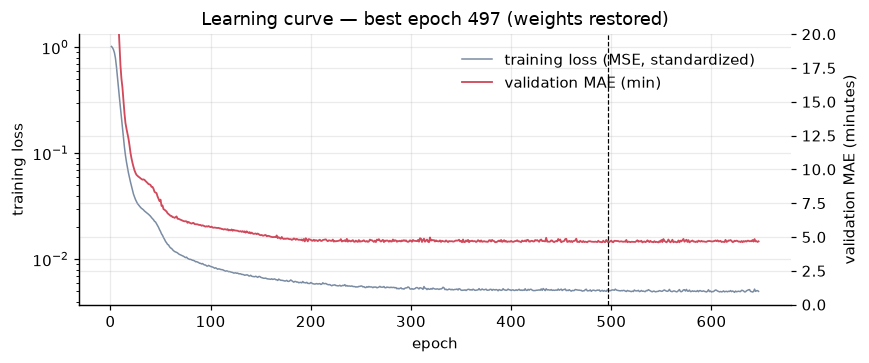

In [9]:
best_overall = min(results.values(), key=lambda r: r.best_val_mae)
small = [r for k, r in results.items() if k[0] == (16, 8)]
best_small = min(small, key=lambda r: r.best_val_mae)
chosen = best_small if best_small.best_val_mae - best_overall.best_val_mae <= 0.2 else best_overall
model = chosen.model
cfg = chosen.config
print(f"best overall: hidden={best_overall.config.hidden} val MAE {best_overall.best_val_mae:.3f}")
print(f"best (16, 8): lr={best_small.config.lr} wd={best_small.config.weight_decay} val MAE {best_small.best_val_mae:.3f}")
print(f"CHOSEN: hidden={cfg.hidden}, lr={cfg.lr}, weight decay={cfg.weight_decay}, "
      f"best epoch {chosen.best_epoch} of {chosen.epochs_run}, val MAE {chosen.best_val_mae:.3f}")
n_params = sum(p.numel() for p in model.parameters())
print("trainable parameters:", n_params)

h = chosen.history
fig, ax1 = plt.subplots(figsize=(8, 3.4))
ax1.plot(h["epoch"], h["trainLoss"], color="#7a8ca3", lw=1, label="training loss (MSE, standardized)")
ax1.set(yscale="log", xlabel="epoch", ylabel="training loss")
ax2 = ax1.twinx()
ax2.plot(h["epoch"], h["valMae"], color="#d1495b", lw=1.2, label="validation MAE (min)")
ax2.axvline(chosen.best_epoch, color="k", ls="--", lw=0.8)
ax2.set(ylabel="validation MAE (minutes)", ylim=(0, 20))
ax1.set_title(f"Learning curve — best epoch {chosen.best_epoch} (weights restored)")
fig.legend(loc="upper right", frameon=False, bbox_to_anchor=(0.88, 0.88))
fig.tight_layout()
fig.savefig(FIG / "learning_curve.png", bbox_inches="tight")
plt.show()

**Locking the choice.** We do not refit on train + validation: validation was used for early stopping, so a refit
would have no principled stopping point. The model above is final — next, the test set is used exactly once.

## 7 · Test-set evaluation (run once)

In [10]:
preds = {name: f(x_te) for name, f in baseline_predict.items()}
preds["nn"] = model.predict(x_te)
labels = {"median_baseline": "Median baseline", "linear": "Linear regression",
          "ratio_formula": "Queue ÷ staff formula", "nn": "Neural network"}

boot = wm.bootstrap_mae(y_te, preds, n_boot=1000)
test_table = pd.DataFrame({labels[k]: {**wm.regression_metrics(y_te, p),
                                        "mae_ci_low": wm.ci95(boot[k])[0], "mae_ci_high": wm.ci95(boot[k])[1]}
                           for k, p in preds.items()}).T
display(test_table.round(3))

diff_nn_median = boot["nn"] - boot["median_baseline"]
diff_nn_linear = boot["nn"] - boot["linear"]
nn_mae = test_table.loc["Neural network", "mae"]
base_mae = test_table.loc["Median baseline", "mae"]
print(f"NN MAE {nn_mae:.2f} vs median baseline {base_mae:.2f} min → "
      f"{100 * (1 - nn_mae / base_mae):.0f}% lower error. "
      f"NN − baseline MAE 95% CI: {wm.ci95(diff_nn_median)}")
print(f"NN − linear MAE 95% CI: {wm.ci95(diff_nn_linear)}")

,mae,rmse,r2,within10,mae_ci_low,mae_ci_high
Median baseline,46.142,71.564,-0.069,0.227,40.306,52.198
Linear regression,26.112,34.175,0.756,0.210,23.682,28.655
Queue ÷ staff formula,5.596,6.739,0.991,0.873,5.180,6.029
Neural network,4.490,5.571,0.994,0.923,4.102,4.881


NN MAE 4.49 vs median baseline 46.14 min → 90% lower error. NN − baseline MAE 95% CI: [-47.70608237584432, -35.817786109447475]
NN − linear MAE 95% CI: [-24.211317850794444, -19.226609947735504]


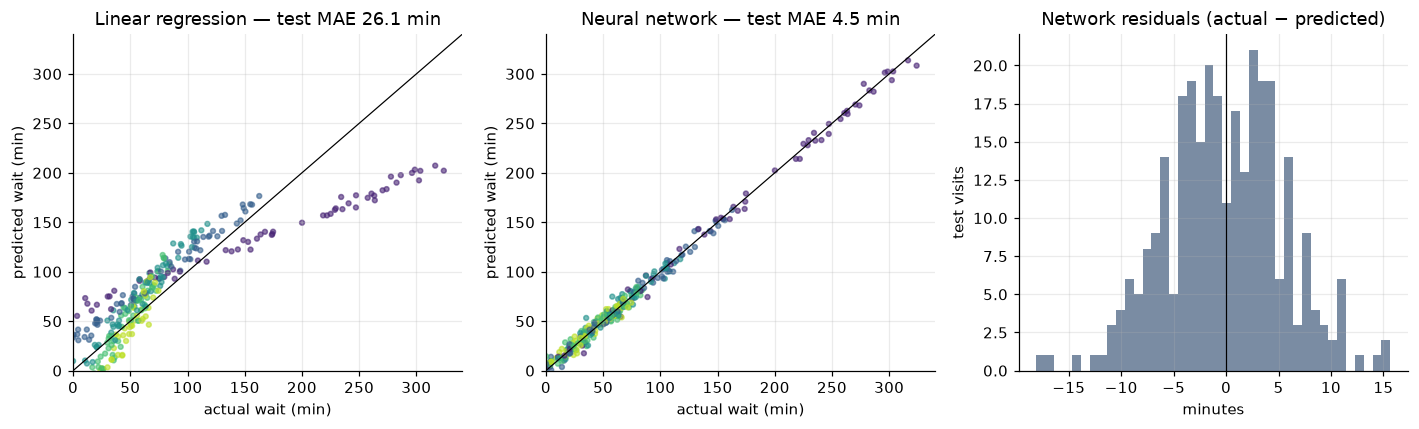


by staff_on_shift


staff_on_shift,1,2,3,4,5
n,59.00,64.00,60.00,61.00,56.00
mae,4.67,4.22,4.68,4.48,4.42
mean_residual,0.97,0.14,-0.92,-0.21,-0.67



by hour


hour,8,9,10,11,12,13,14,15,16,17
n,32.00,36.00,29.00,33.00,15.00,32.00,26.00,36.0,30.00,31.00
mae,3.48,5.39,4.26,4.31,4.73,4.48,4.67,4.8,4.99,3.79
mean_residual,1.15,2.56,-0.38,-0.09,-3.29,-0.80,-0.71,-0.2,-2.47,0.65



by day_of_week


day_of_week,Mon,Tue,Wed,Thu,Fri
n,57.00,59.00,58.00,58.00,68.00
mae,5.11,4.17,4.43,4.07,4.65
mean_residual,-0.94,0.49,-1.17,0.63,0.24


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
lim = (0, max(y_te.max(), preds["nn"].max()) * 1.05)
for ax, key in zip(axes[:2], ["linear", "nn"]):
    ax.scatter(y_te, preds[key], s=10, alpha=0.6,
               c=[STAFF_COLORS[int(s)] for s in x_te[:, 2]])
    ax.plot(lim, lim, color="k", lw=0.8)
    m = wm.regression_metrics(y_te, preds[key])
    ax.set(xlim=lim, ylim=lim, xlabel="actual wait (min)", ylabel="predicted wait (min)",
           title=f"{labels[key]} — test MAE {m['mae']:.1f} min")
res_nn = y_te - preds["nn"]
ax = axes[2]
ax.hist(res_nn, bins=40, color="#7a8ca3")
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Network residuals (actual − predicted)", xlabel="minutes", ylabel="test visits")
fig.tight_layout()
fig.savefig(FIG / "test_predictions.png", bbox_inches="tight")
plt.show()

te = test.copy()
te["nn"] = preds["nn"]
te["abs_err"] = (te["nn"] - te["wait_minutes"]).abs()
te["residual"] = te["wait_minutes"] - te["nn"]
for col in ["staff_on_shift", "hour", "day_of_week"]:
    g = te.groupby(col).agg(n=("abs_err", "size"), mae=("abs_err", "mean"), mean_residual=("residual", "mean"))
    if col == "day_of_week":
        g = g.reindex(wm.DAYS)
    print(f"\nby {col}"); display(g.round(2).T)

Reading the results:

* The network beats the required **median baseline** by a wide margin (about 90% lower MAE), and the
  straight-line **linear regression** too — the bootstrap 95% intervals for both differences exclude zero.
  A straight line in the raw inputs cannot represent "÷ staff"; the network can.
* It even beats the **queue ÷ staff formula**, because it also learned the hour and weekday effects the formula ignores.
* The errors are roughly the same size everywhere (similar MAE for every staffing level, hour and weekday), so the
  leftover ~4–5 minutes looks like random noise the four inputs cannot explain rather than a pattern the model missed.
  The exhibit shows each prediction with a "typical range" taken from the validation residuals (10th–90th percentile).

## 8 · The biggest mistake

In [12]:
miss_idx = te["abs_err"].idxmax()
miss = te.loc[miss_idx]
same_cell = train[(train["staff_on_shift"] == miss["staff_on_shift"]) &
                  (train["patients_in_queue"] == miss["patients_in_queue"])]
same_cell_time = same_cell[(same_cell["hour"] == miss["hour"])]
ratio_pred_miss = float(ratio_model.predict(np.array([[miss["patients_in_queue"] / miss["staff_on_shift"]]]))[0])
print("Largest absolute test error:")
display(miss[["hour", "day_of_week", "staff_on_shift", "patients_in_queue", "wait_minutes", "nn", "abs_err"]].to_frame().T)
print(f"median baseline would have said {median_wait:.1f} min; queue÷staff formula says {ratio_pred_miss:.1f} min")
print(f"\ntraining visits with the same staff ({int(miss['staff_on_shift'])}) and queue ({int(miss['patients_in_queue'])}): "
      f"n={len(same_cell)}, mean {same_cell['wait_minutes'].mean():.1f}, "
      f"range {same_cell['wait_minutes'].min():.1f}–{same_cell['wait_minutes'].max():.1f} min")
display(same_cell.sort_values("wait_minutes")[["hour", "day_of_week", "staff_on_shift", "patients_in_queue", "wait_minutes"]])

# How noisy is this staffing level in general? Spread of the formula's residuals on training data.
cell_staff = train[train["staff_on_shift"] == miss["staff_on_shift"]]
resid_staff = cell_staff["wait_minutes"] - ratio_model.predict(ratio_feature(wm.inputs(cell_staff)))
print(f"\nnoise check — formula residual std for {int(miss['staff_on_shift'])}-staff training visits: {resid_staff.std():.1f} min")

Largest absolute test error:


,hour,day_of_week,staff_on_shift,patients_in_queue,wait_minutes,nn,abs_err
1681,13,Wed,3,9,35.2,53.279762,18.079762


median baseline would have said 59.5 min; queue÷staff formula says 53.9 min

training visits with the same staff (3) and queue (9): n=6, mean 58.1, range 51.8–69.3 min


,hour,day_of_week,staff_on_shift,patients_in_queue,wait_minutes
1573,12,Tue,3,9,51.8
941,8,Fri,3,9,53.0
1221,15,Mon,3,9,56.8
1547,16,Fri,3,9,58.3
1091,8,Thu,3,9,59.6
1434,17,Mon,3,9,69.3



noise check — formula residual std for 3-staff training visits: 6.5 min


**Reading the mistake.** The worst test prediction is a **Wednesday 1 pm visit with 3 staff and 9 patients
queued**. The visitor actually waited **35.2 minutes**; the network said **53.3** — 18 minutes too long.

* **The network followed the evidence.** The 6 training visits with the same staff and queue waited
  51.8–69.3 minutes (mean 58.1), and the queue ÷ staff formula says 53.9. Because 1 pm on a Wednesday is an
  off-peak, non-Monday slot, the network shaded its answer a little *below* those neighbours — the right direction.
* **The visit itself was unusual.** 35.2 minutes is faster than *every* comparable training visit. Waits at this
  staffing level scatter about 6.5 minutes (one standard deviation) around the trend, and this visit sits almost
  three of those below it. Among 300 test visits, one outlier like this is roughly what chance alone produces.
* So the error is mostly **noise the four inputs cannot see**. In a real clinic that might be a no-show, a patient
  who left, or an unusually quick visit type; in this synthetic data it is simply the random part of the simulation.

**What might have helped**

1. **More informative inputs** — visit type, arrivals in the last hour, no-shows. Nothing in hour / day / staff /
   queue can predict this one visit's luck.
2. **Predicting a range, not just a number** — quantile or interval outputs (or the validation-based "typical range"
   the exhibit shows) would tell a visitor that a ~35-minute wait was possible.
3. **More data in sparse settings** — only 6 training visits share this staff/queue setting, and none of them were
   on a Wednesday or at 1 pm.

In [13]:
MISS_EXPLANATION = (
    "This visit was quicker than all 6 training visits with the same staff and queue (51.8-69.3 min). "
    "The network predicted close to those similar visits; the gap is random variation that hour, day, staff "
    "and queue cannot explain. Extra inputs (visit type, recent arrivals, no-shows) or predicting a range "
    "instead of a single number would have helped."
)
biggest_miss = {
    "inputs": {"hour": int(miss["hour"]), "day": miss["day_of_week"], "dayIdx": int(miss["day_idx"]),
               "staff": int(miss["staff_on_shift"]), "queue": int(miss["patients_in_queue"])},
    "actual": wm.r(miss["wait_minutes"]), "nn": wm.r(miss["nn"]), "baseline": wm.r(median_wait),
    "ratioFormula": wm.r(ratio_pred_miss), "error": wm.r(miss["nn"] - miss["wait_minutes"]),
    "trainNeighbors": {"n": int(len(same_cell)), "mean": wm.r(same_cell["wait_minutes"].mean()),
                       "min": wm.r(same_cell["wait_minutes"].min()), "max": wm.r(same_cell["wait_minutes"].max())},
    "explanation": MISS_EXPLANATION,
}
biggest_miss

{'inputs': {'hour': 13, 'day': 'Wed', 'dayIdx': 2, 'staff': 3, 'queue': 9},
 'actual': 35.2,
 'nn': 53.28,
 'baseline': 59.5,
 'ratioFormula': 53.89,
 'error': 18.08,
 'trainNeighbors': {'n': 6, 'mean': 58.13, 'min': 51.8, 'max': 69.3},
 'explanation': 'This visit was quicker than all 6 training visits with the same staff and queue (51.8-69.3 min). The network predicted close to those similar visits; the gap is random variation that hour, day, staff and queue cannot explain. Extra inputs (visit type, recent arrivals, no-shows) or predicting a range instead of a single number would have helped.'}

## 9 · What the network learned — the exhibit's discovery

Hold the queue at 12 patients on a Monday at 9 am and change only the staff on shift.

1 staff →  198.2 min
2 staff →  100.0 min
3 staff →   76.4 min
4 staff →   57.7 min
5 staff →   51.0 min
minutes saved by each added staff member: [(1, 2, 98.2), (2, 3, 23.6), (3, 4, 18.7), (4, 5, 6.8)]


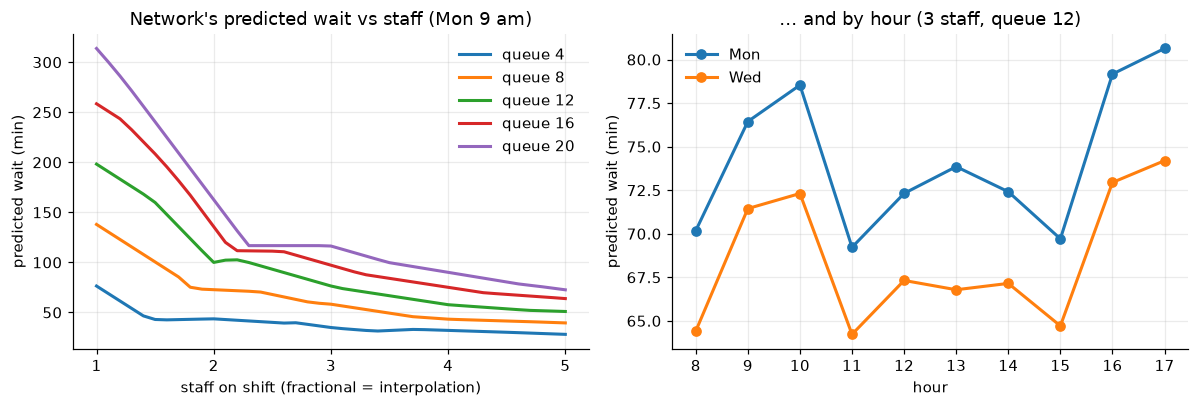

learned mean prediction by hour: {8.0: 74.1, 9.0: 81.3, 10.0: 82.7, 11.0: 74.3, 12.0: 75.7, 13.0: 74.8, 14.0: 74.8, 15.0: 74.4, 16.0: 82.0, 17.0: 83.1}
peak hours (>3% above average): [9, 10, 16, 17]
Monday vs other weekdays: +5.0%


In [14]:
scenario = {"hour": 9, "day": "Mon", "dayIdx": 0, "queue": 12}
xs = np.array([[scenario["hour"], scenario["dayIdx"], s, scenario["queue"]] for s in wm.STAFF], dtype=np.float32)
wait_by_staff = model.predict(xs)
savings = [{"from": s, "to": s + 1, "minutes": wm.r(wait_by_staff[i] - wait_by_staff[i + 1], 1)} for i, s in enumerate(wm.STAFF[:-1])]
for s, w in zip(wm.STAFF, wait_by_staff):
    print(f"{s} staff → {w:6.1f} min")
print("minutes saved by each added staff member:", [(d['from'], d['to'], d['minutes']) for d in savings])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for q in [4, 8, 12, 16, 20]:
    xq = np.array([[9, 0, s, q] for s in np.linspace(1, 5, 41)], dtype=np.float32)
    ax.plot(np.linspace(1, 5, 41), model.predict(xq), lw=2, label=f"queue {q}")
ax.set(title="Network's predicted wait vs staff (Mon 9 am)", xlabel="staff on shift (fractional = interpolation)",
       ylabel="predicted wait (min)", xticks=wm.STAFF)
ax.legend(frameon=False)

ax = axes[1]
hours = np.array(wm.HOURS)
hour_profile = {}
for d, name in [(0, "Mon"), (2, "Wed")]:
    xh = np.array([[h, d, 3, 12] for h in hours], dtype=np.float32)
    p = model.predict(xh)
    hour_profile[name] = p
    ax.plot(hours, p, marker="o", lw=2, label=name)
ax.set(title="… and by hour (3 staff, queue 12)", xlabel="hour", ylabel="predicted wait (min)", xticks=wm.HOURS)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "learned_patterns.png", bbox_inches="tight")
plt.show()

# Learned weekly patterns averaged over the whole input space (from the full prediction grid)
grid_x = wm.grid_inputs()
grid_pred = model.predict(grid_x)
grid_df = pd.DataFrame(grid_x, columns=["hour", "day_idx", "staff", "queue"]).assign(pred=grid_pred)
learned_hour = grid_df.groupby("hour")["pred"].mean()
learned_day = grid_df.groupby("day_idx")["pred"].mean()
peak_hours = [int(h) for h, v in learned_hour.items() if v > learned_hour.mean() * 1.03]
monday_lift = float(learned_day.loc[0] / learned_day.loc[1:].mean() - 1)
print("learned mean prediction by hour:", learned_hour.round(1).to_dict())
print("peak hours (>3% above average):", peak_hours)
print(f"Monday vs other weekdays: {100 * monday_lift:+.1f}%")

**What the network discovered.** Without ever being told about "queue ÷ staff", the network reproduces it:
at a 12-patient queue, the 2nd staff member cuts the predicted wait by about 98 minutes, while the 5th saves about 7 —
**diminishing returns**. It also picked up the busier hours (9–10 am and 4–5 pm) and the Monday bump.

**A caution visible in the left plot:** between whole numbers of staff the curves kink and flatten. The network
only ever saw 1, 2, 3, 4 or 5 staff, so its output at "2.5 staff" is an untested guess. The exhibit therefore draws
its 3-D landscape *through the network's predictions at whole staff numbers* (with a smooth, shape-preserving
interpolation between them) and only lets visitors choose whole staff numbers.

## 10 · Export to ONNX, verify, and write the web artifacts

The exported graph keeps the preprocessing inside it and exposes the two hidden layers (`h1`, `h2`) as extra
outputs, so the exhibit can light up individual neurons. We check the ONNX file against PyTorch on every one of
the 5,250 possible input combinations.

In [15]:
onnx_path = wm.WEB_PUBLIC / "model" / "wait_mlp.onnx"
wm.export_onnx(model, onnx_path)
onnx.checker.check_model(onnx.load(str(onnx_path)))
ort_grid = wm.ort_run(onnx_path, grid_x)
max_diff = float(np.abs(ort_grid["wait_minutes"].ravel() - grid_pred).max())
print(f"ONNX file: {onnx_path.name}, {onnx_path.stat().st_size:,} bytes")
print("graph ops:", sorted({n.op_type for n in onnx.load(str(onnx_path)).graph.node}))
print(f"max |ONNX − PyTorch| over all 5,250 grid inputs: {max_diff:.2e} minutes")
assert max_diff < 1e-4

ONNX file: wait_mlp.onnx, 19,291 bytes
graph ops: ['Add', 'Cast', 'Clip', 'Concat', 'Div', 'Equal', 'Gemm', 'Mul', 'Relu', 'Round', 'Slice', 'Sub']
max |ONNX − PyTorch| over all 5,250 grid inputs: 6.10e-05 minutes


In [16]:
DATA_OUT = wm.WEB_DATA
nn_val_pred = model.predict(x_va)
r = wm.r

def model_entry(key, extra=None):
    return {
        "label": labels[key],
        "val": {k: r(v, 4) for k, v in wm.regression_metrics(y_va, (nn_val_pred if key == "nn" else baseline_predict[key](x_va))).items()},
        "test": {k: r(v, 4) for k, v in wm.regression_metrics(y_te, preds[key]).items()},
        "ci95": {"mae": [r(v, 3) for v in wm.ci95(boot[key])]},
        **({"extra": extra} if extra else {}),
    }

residuals_by = {}
for col, key in [("hour", "hour"), ("day_of_week", "day"), ("staff_on_shift", "staff")]:
    g = te.groupby(col).agg(n=("abs_err", "size"), mae=("abs_err", "mean"), meanResidual=("residual", "mean"))
    if col == "day_of_week":
        g = g.reindex(wm.DAYS)
    residuals_by[key] = [{"key": (k if isinstance(k, str) else int(k)), "n": int(v.n), "mae": r(v.mae), "meanResidual": r(v.meanResidual)}
                         for k, v in g.iterrows()]

metrics = {
    "schemaVersion": 1,
    "generatedAt": pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ"),
    "dataset": {
        "name": "clinic-wait-times.csv", "source": wm.DATA_SOURCE_URL, "synthetic": True, "rows": int(len(df)),
        "sha256": sha,
        "ranges": {"hour": [8, 17], "day": wm.DAYS, "staff": [1, 5], "queue": [0, 20],
                   "wait": [r(df.wait_minutes.min()), r(df.wait_minutes.max())]},
        "meanWaitByStaff": {int(k): r(v, 1) for k, v in df.groupby("staff_on_shift")["wait_minutes"].mean().items()},
        "split": {"train": len(train), "val": len(val), "test": len(test), "seed": wm.SEED, "stratifiedBy": "staff_on_shift"},
    },
    "target": {"trainMedian": r(median_wait), "trainMean": r(scaling.y_mean), "trainStd": r(scaling.y_std)},
    "models": {
        "median_baseline": model_entry("median_baseline", {"value": r(median_wait)}),
        "linear": model_entry("linear"),
        "ratio_formula": model_entry("ratio_formula", {"slope": r(ratio_model.coef_[0], 3), "intercept": r(ratio_model.intercept_, 3)}),
        "nn": model_entry("nn", {"hidden": list(cfg.hidden), "parameters": int(n_params)}),
    },
    "headline": {
        "nnMae": r(nn_mae), "baselineMae": r(base_mae), "linearMae": r(test_table.loc["Linear regression", "mae"]),
        "maeReductionPct": r(100 * (1 - nn_mae / base_mae), 1),
        "maeDiffCI95": [r(v) for v in wm.ci95(diff_nn_median)],
        "nnWithin10Pct": r(100 * test_table.loc["Neural network", "within10"], 1),
        "nnR2": r(test_table.loc["Neural network", "r2"], 3),
    },
    "discovery": {
        "scenario": scenario,
        "waitByStaff": [{"staff": s, "pred": r(w, 1)} for s, w in zip(wm.STAFF, wait_by_staff)],
        "savings": savings,
        "peakHours": peak_hours,
        "mondayLiftPct": r(100 * monday_lift, 1),
        "learnedMeanByHour": {int(k): r(v, 1) for k, v in learned_hour.items()},
        "learnedMeanByDay": {wm.DAYS[int(k)]: r(v, 1) for k, v in learned_day.items()},
    },
    "residualBands": wm.residual_bands(y_va, nn_val_pred),
    "biggestMiss": biggest_miss,
    "residualsBy": residuals_by,
}
wm.write_json(DATA_OUT / "metrics.json", metrics, indent=2)

test_rows = [[int(i), int(row.hour), int(row.day_idx), int(row.staff_on_shift), int(row.patients_in_queue),
              r(row.wait_minutes), r(pn), r(pl), r(pr), r(median_wait)]
             for (i, row), pn, pl, pr in zip(test.iterrows(), preds["nn"], preds["linear"], preds["ratio_formula"])]
wm.write_json(DATA_OUT / "test_predictions.json", {
    "columns": ["id", "hour", "day", "staff", "queue", "actual", "nn", "linear", "ratio", "baseline"],
    "biggestMissId": int(miss_idx), "rows": test_rows})

wm.write_json(DATA_OUT / "grid_predictions.json", {
    "order": "hour,day,staff,queue", "hours": wm.HOURS, "days": wm.DAYS, "staff": wm.STAFF, "queue": wm.QUEUE,
    "wait": [r(v) for v in ort_grid["wait_minutes"].ravel()]})

sd = model.state_dict()
wm.write_json(DATA_OUT / "model_card.json", {
    "onnx": {"file": "model/wait_mlp.onnx", "opset": 18, "bytes": onnx_path.stat().st_size,
             "input": {"name": "x", "shape": ["batch", 4], "columns": ["hour", "dayIdx (0=Mon)", "staff", "queue"]},
             "outputs": [{"name": "wait_minutes", "shape": ["batch", 1]}, {"name": "h1", "shape": ["batch", cfg.hidden[0]]},
                         {"name": "h2", "shape": ["batch", cfg.hidden[1]]}]},
    "encoding": {"hours": wm.HOURS, "dayLabels": wm.DAYS,
                 "numeric": {"staff": {"mean": scaling.num_mean[0], "std": scaling.num_std[0]},
                             "queue": {"mean": scaling.num_mean[1], "std": scaling.num_std[1]}},
                 "target": {"mean": scaling.y_mean, "std": scaling.y_std}, "clampMin": 0},
    "featureNames": wm.FEATURE_NAMES,
    "layers": [{"name": "input", "size": len(wm.FEATURE_NAMES)}, {"name": "h1", "size": cfg.hidden[0], "activation": "relu"},
               {"name": "h2", "size": cfg.hidden[1], "activation": "relu"}, {"name": "output", "size": 1, "activation": "linear"}],
    "weightsForDiagram": {k: np.round(sd[f"{k}.weight"].numpy(), 4).tolist() for k in ["l1", "l2", "out"]},
    "training": {"optimizer": "Adam", "loss": "MSE (standardized target)", "lr": cfg.lr, "weightDecay": cfg.weight_decay,
                 "batch": cfg.batch_size, "maxEpochs": cfg.max_epochs, "patience": cfg.patience,
                 "bestEpoch": chosen.best_epoch, "epochsRun": chosen.epochs_run, "parameters": int(n_params),
                 "sweep": [{k: (r(v, 4) if isinstance(v, float) else v) for k, v in s.items()} for s in sweep]},
    "versions": versions,
})

wm.write_json(DATA_OUT / "training_history.json", {
    "epoch": h["epoch"], "trainLoss": [r(v, 5) for v in h["trainLoss"]], "valMae": [r(v, 3) for v in h["valMae"]],
    "bestEpoch": chosen.best_epoch})

px = wm.parity_inputs()
ort_px = wm.ort_run(onnx_path, px)
wm.write_json(wm.WEB_FIXTURES / "parity_fixtures.json", {
    "inputs": px.astype(int).tolist(), "wait": ort_px["wait_minutes"].ravel().tolist(),
    "h1": ort_px["h1"].tolist(), "h2": ort_px["h2"].tolist()})

for p in sorted([*DATA_OUT.glob("*.json"), wm.WEB_FIXTURES / "parity_fixtures.json"]):
    print(f"{p.name:24s} {p.stat().st_size:>9,} bytes")

grid_predictions.json       37,540 bytes
metrics.json                 7,558 bytes
model_card.json             11,192 bytes
test_predictions.json       16,443 bytes
training_history.json       13,413 bytes
parity_fixtures.json        25,620 bytes


## Key numbers (used by the exhibit's guide and chatbot)

In [17]:
print(json.dumps({"headline": metrics["headline"], "discovery": {k: metrics["discovery"][k] for k in ["scenario", "waitByStaff", "savings", "peakHours", "mondayLiftPct"]},
                  "biggestMiss": {k: biggest_miss[k] for k in ["inputs", "actual", "nn", "error", "trainNeighbors"]}}, indent=1))

{
 "headline": {
  "nnMae": 4.49,
  "baselineMae": 46.14,
  "linearMae": 26.11,
  "maeReductionPct": 90.3,
  "maeDiffCI95": [
   -47.71,
   -35.82
  ],
  "nnWithin10Pct": 92.3,
  "nnR2": 0.994
 },
 "discovery": {
  "scenario": {
   "hour": 9,
   "day": "Mon",
   "dayIdx": 0,
   "queue": 12
  },
  "waitByStaff": [
   {
    "staff": 1,
    "pred": 198.2
   },
   {
    "staff": 2,
    "pred": 100.0
   },
   {
    "staff": 3,
    "pred": 76.4
   },
   {
    "staff": 4,
    "pred": 57.7
   },
   {
    "staff": 5,
    "pred": 51.0
   }
  ],
  "savings": [
   {
    "from": 1,
    "to": 2,
    "minutes": 98.2
   },
   {
    "from": 2,
    "to": 3,
    "minutes": 23.6
   },
   {
    "from": 3,
    "to": 4,
    "minutes": 18.7
   },
   {
    "from": 4,
    "to": 5,
    "minutes": 6.8
   }
  ],
  "peakHours": [
   9,
   10,
   16,
   17
  ],
  "mondayLiftPct": 5.0
 },
 "biggestMiss": {
  "inputs": {
   "hour": 13,
   "day": "Wed",
   "dayIdx": 2,
   "staff": 3,
   "queue": 9
  },
  "actual": 35.2